In [3]:
import seaborn as sns
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")
print(df)

                  pickup             dropoff  passengers  distance  fare  \
0    2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0   
1    2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0   
2    2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5   
3    2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0   
4    2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0   
...                  ...                 ...         ...       ...   ...   
6428 2019-03-31 09:51:53 2019-03-31 09:55:27           1      0.75   4.5   
6429 2019-03-31 17:38:00 2019-03-31 18:34:23           1     18.74  58.0   
6430 2019-03-23 22:55:18 2019-03-23 23:14:25           1      4.14  16.0   
6431 2019-03-04 10:09:25 2019-03-04 10:14:29           1      1.12   6.0   
6432 2019-03-13 19:31:22 2019-03-13 19:48:02           1      3.85  15.0   

       tip  tolls  total   color      payment            pickup_zone  \
0     2.15    0

In [5]:
# Checking missing values
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print("Missing values by column:")
display(missing_values)

Missing values by column:


dropoff_zone       45
dropoff_borough    45
payment            44
pickup_zone        26
pickup_borough     26
dtype: int64

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [16]:
#median 
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

    

In [15]:
#mode

cat_cols = df.select_dtypes(include="str").columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [18]:
#removing

df = df.dropna(subset=["pickup"])

In [19]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

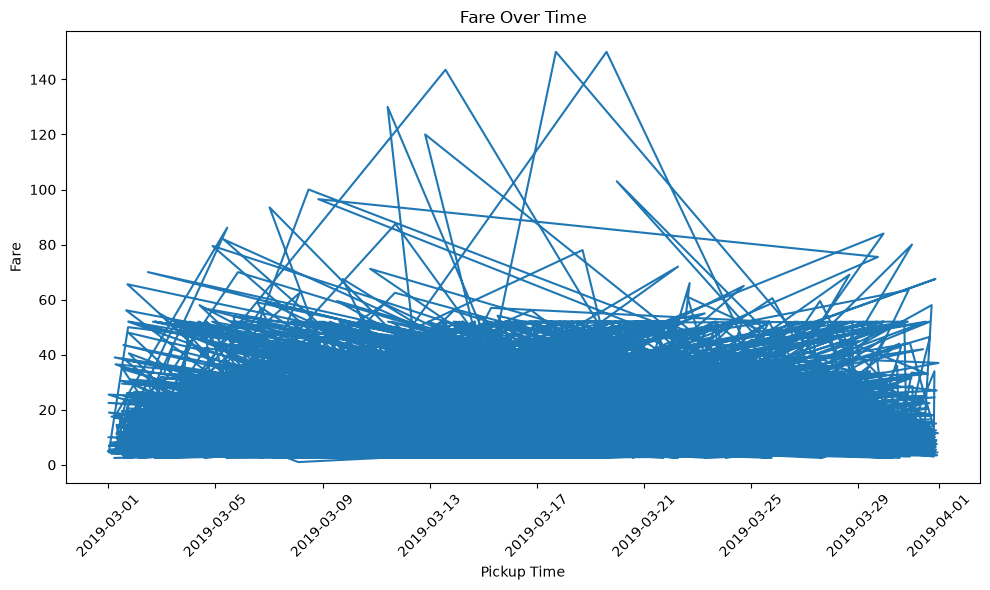

In [20]:
#Visualisation using matplotlib plot

#Line chart

plt.figure(figsize=(10, 6))

plt.plot(df["pickup"], df["fare"])

plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


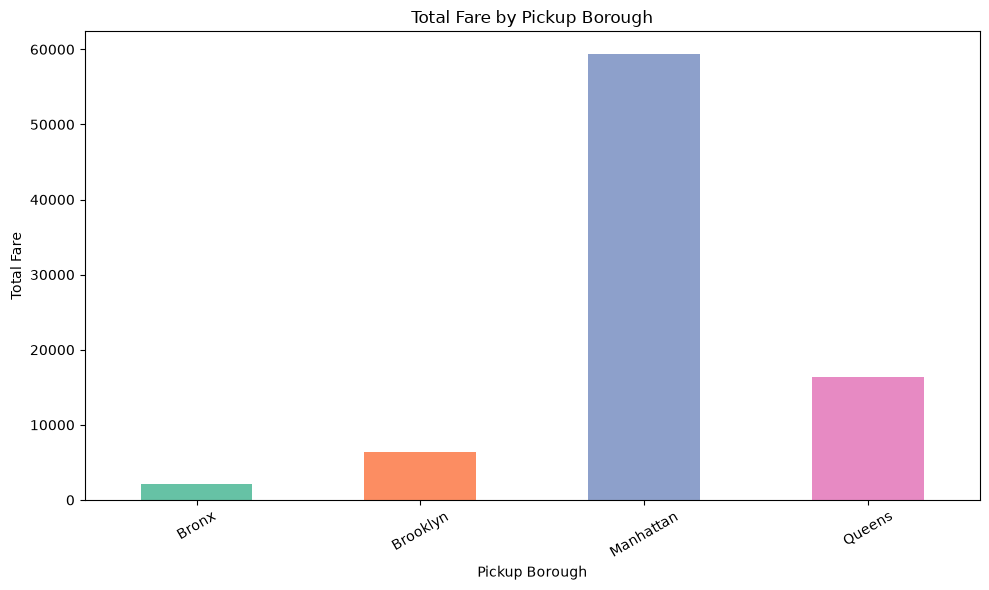

In [21]:
#Bar chart 

borough_fare = df.groupby("pickup_borough")["fare"].sum()

plt.figure(figsize=(10, 6))

borough_fare.plot(
    kind="bar",
    color=sns.color_palette("Set2")
)

plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

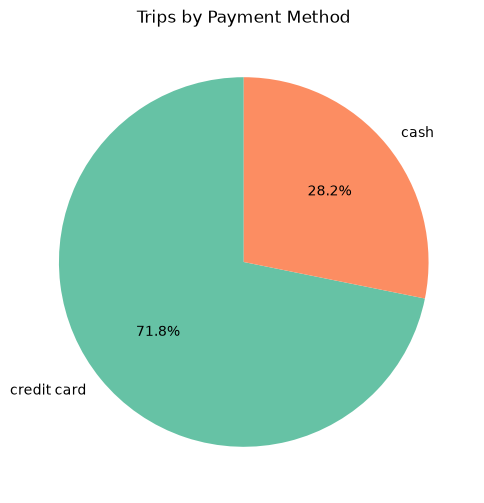

In [22]:
#Pie chart 

payment_count = df["payment"].value_counts()

plt.figure(figsize=(10, 6))

plt.pie(
    payment_count,
    labels=payment_count.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2")
)

plt.title("Trips by Payment Method")
plt.show()


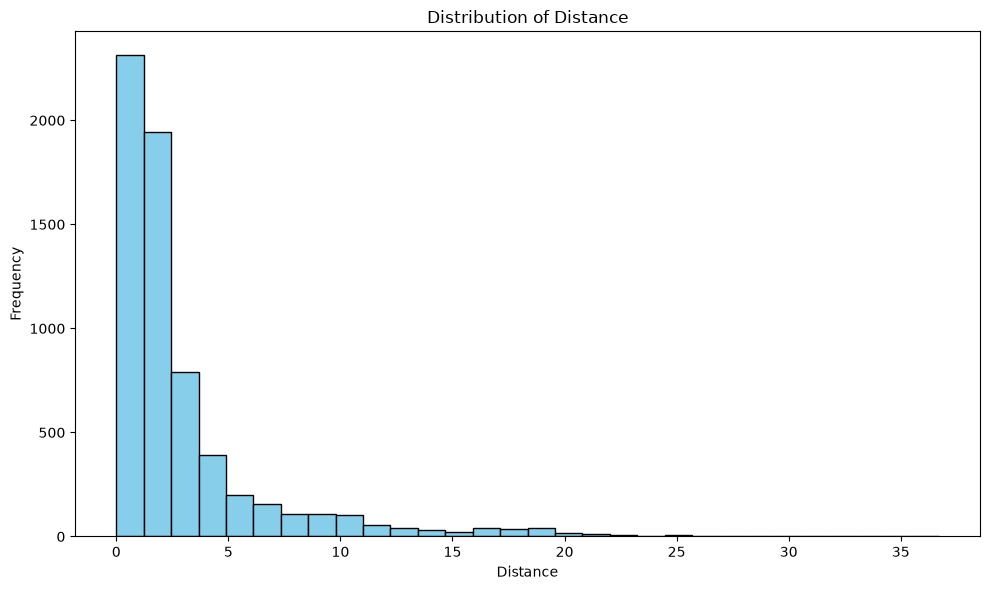

In [23]:
#Histogram
plt.figure(figsize=(10, 6))

plt.hist(
    df["distance"],
    bins=30,
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribution of Distance")
plt.xlabel("Distance")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

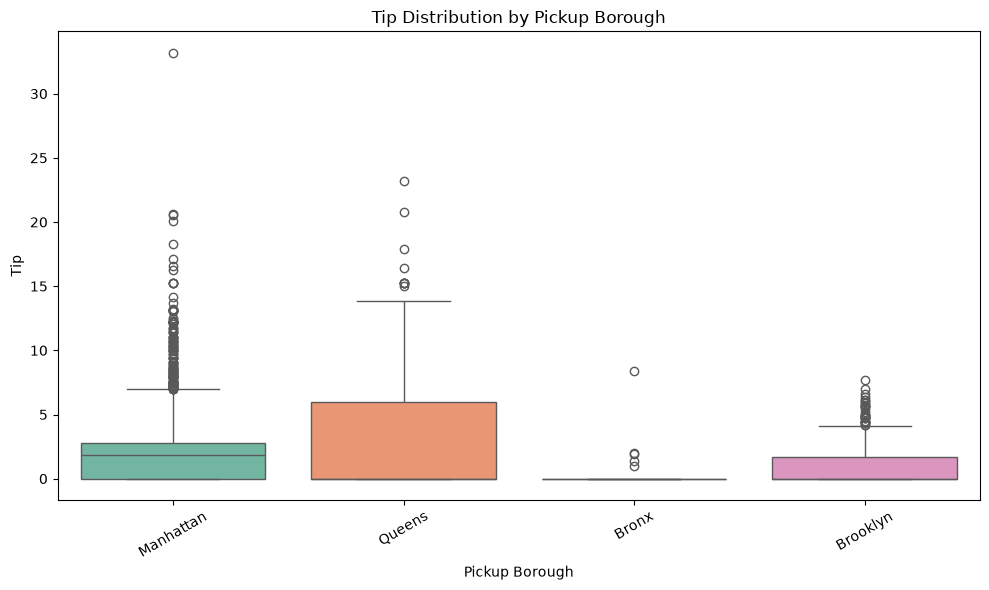

In [24]:
#Box Plot

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="pickup_borough",
    y="tip",
    hue="pickup_borough",
    palette="Set2",
    legend=False
)

plt.title("Tip Distribution by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

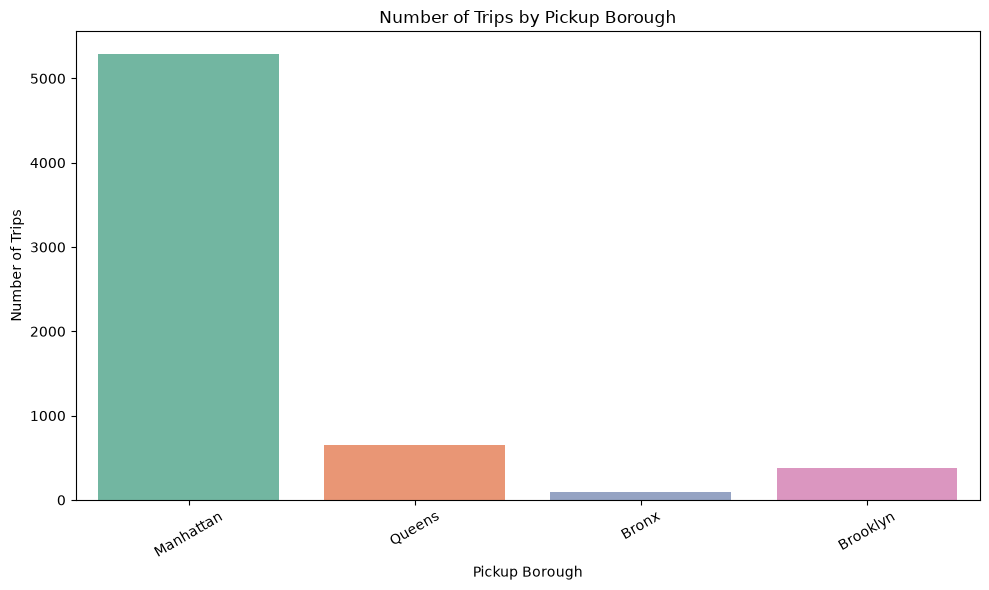

In [25]:
#Visualisations using seaborn

#Count Plot

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="pickup_borough",
    hue="pickup_borough",
    palette="Set2",
    legend=False
)

plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

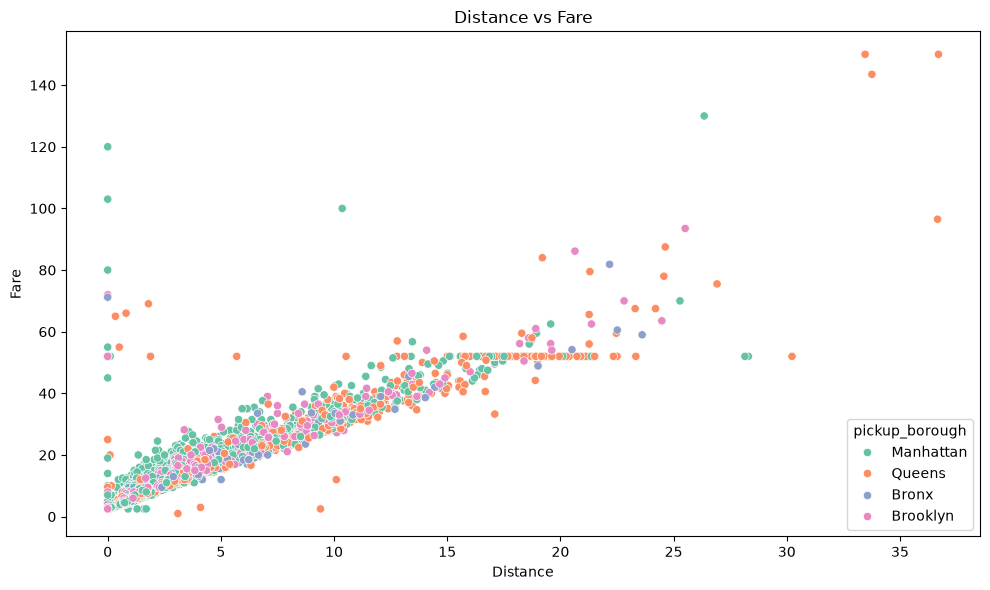

In [26]:
#Scatter Plot

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough",
    palette="Set2"
)

plt.title("Distance vs Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")

plt.tight_layout()
plt.show()

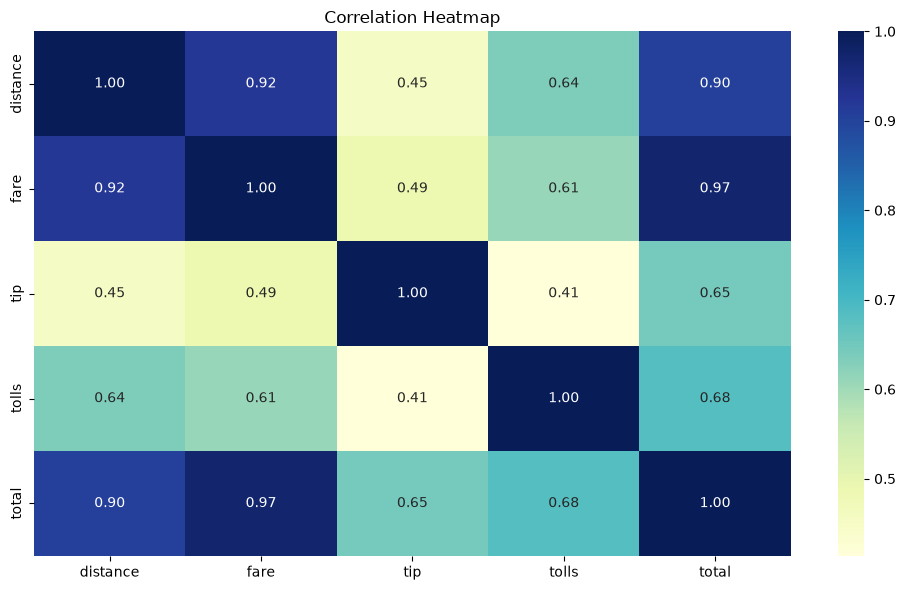

In [27]:
#Heatmap
corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

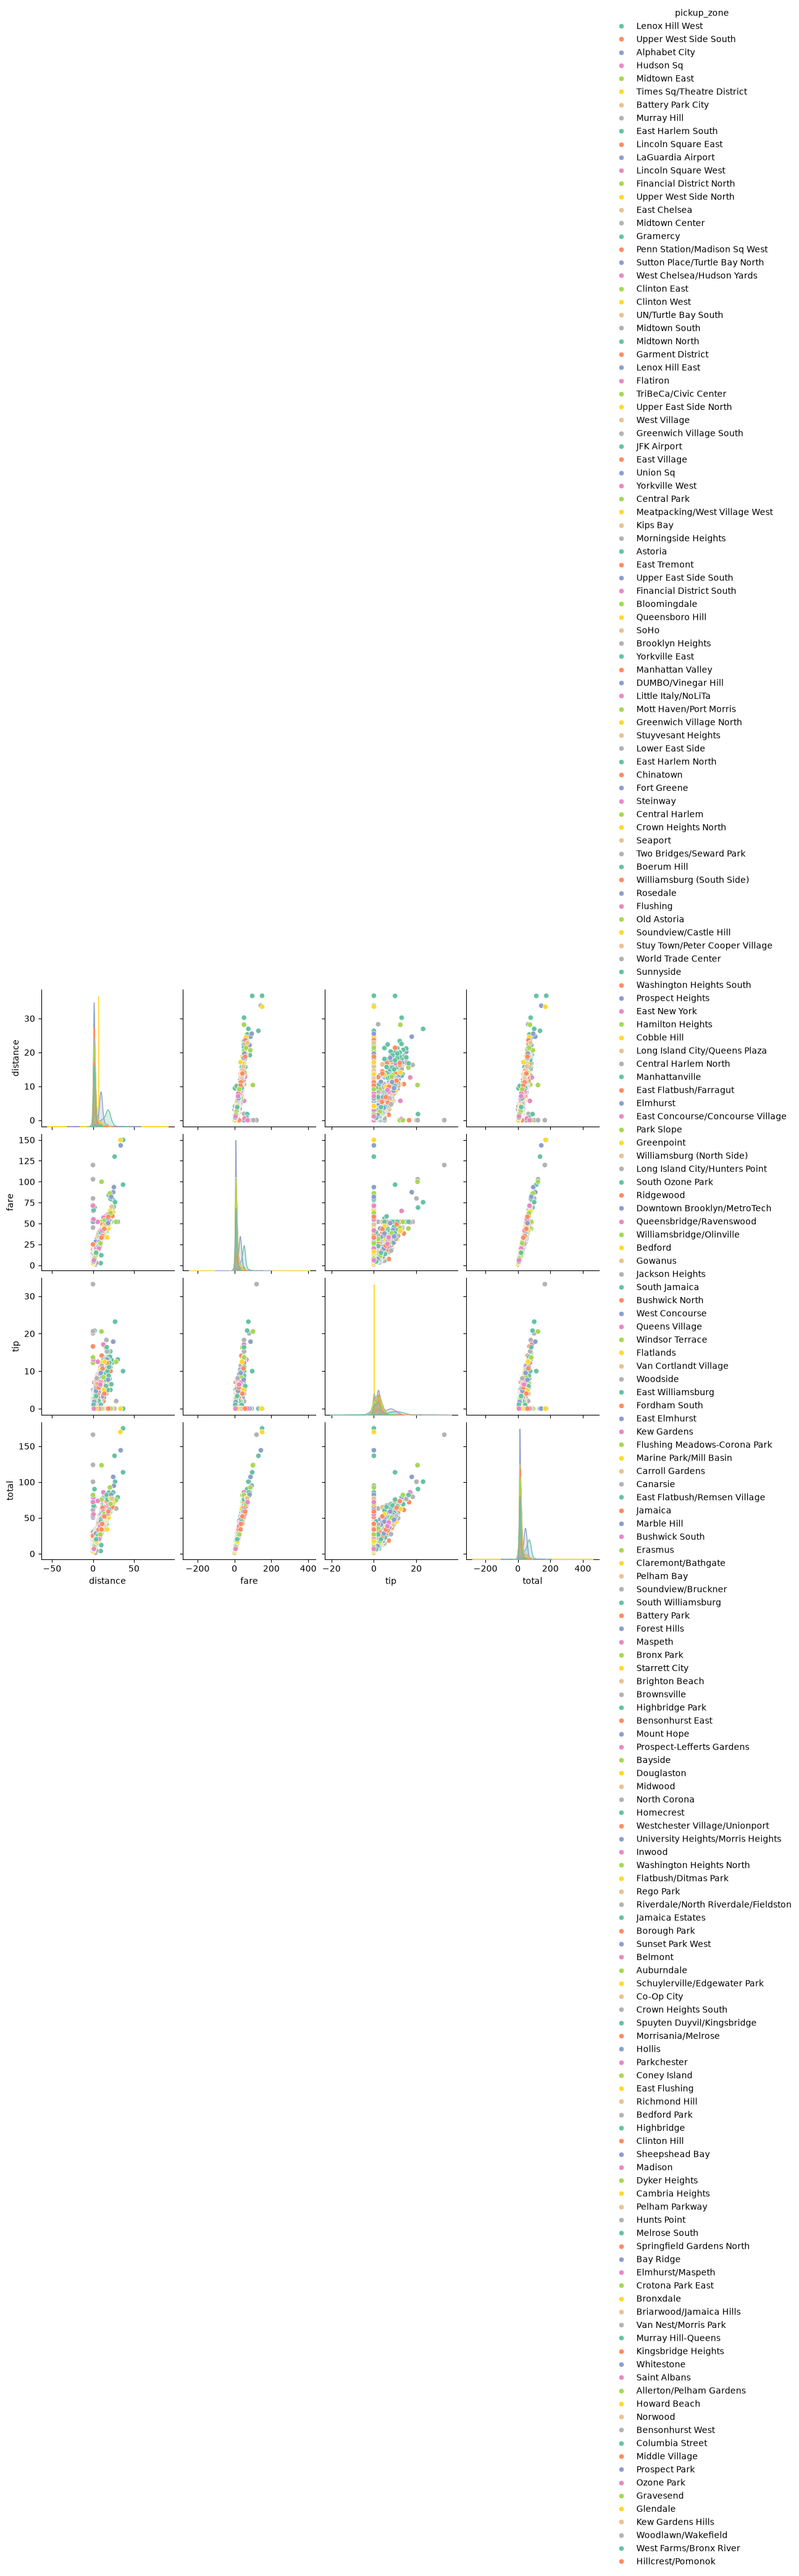

In [30]:
#Pair Plot
sns.pairplot(
    df,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    palette="Set2"
)

plt.show()

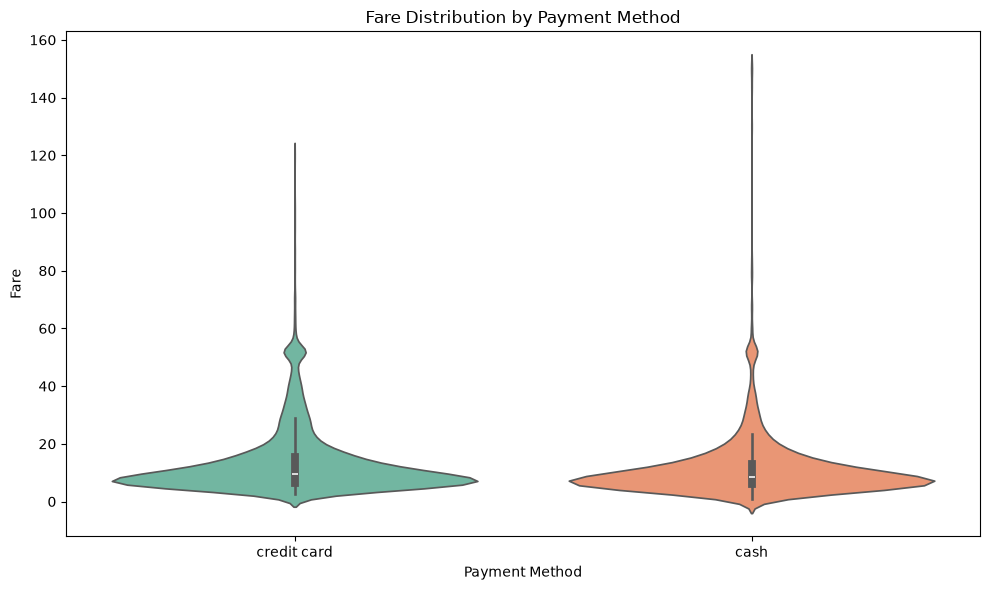

In [31]:
#Violin Plot

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="payment",
    y="fare",
    hue="payment",
    palette="Set2",
    legend=False
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")

plt.tight_layout()
plt.show()

In [35]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [36]:
df.shape


(6433, 14)